# 1 Proyecto: 5. Sistema de optimizacion de rutas de distribucion
Fundamentos de IA - Algortimo genetico para encontrar la ruta mas corta entre un punto de partida y 15 destinos en Aguascalientes.

## 0. Librerias y parametros

In [1]:
import  numpy as np
import matplotlib.pyplot as plt
import random

SEMILLA = 17
TAMANO_POBLACION = 100
GENERACIONES = 500
TASA_CRUCE = 0.9
TASA_MUTACION = 0.05
TAM_TORNEO = 5
NUM_ELITES = 2
random.seed(SEMILLA)
np.random.seed(SEMILLA)


## 1. Datos: punto de partida y destinos 


In [2]:
puntos = [
    {"nombre": "Abedul (Punto partida)", "latitud": 21.901101424443024, "longitud": -102.3040012533693},
    {"nombre": "The Home Depot", "latitud": 21.853087360458733, "longitud": -102.29388398860823},
    {"nombre": "H-E-B Santa Monica", "latitud": 21.84553768519487, "longitud": -102.32043895938828},
    {"nombre": "Walmart Express", "latitud": 21.862315711269652, "longitud": -102.33978794910628},
    {"nombre": "Centro Comercial Altaria", "latitud": 21.92561581878823, "longitud": -102.29019621691815},
    {"nombre": "Refaccionaria Autozone", "latitud": 21.917045413444306, "longitud": -102.25331493638625},
    {"nombre": "Costco Wholesale", "latitud": 21.91798172418564, "longitud": -102.28859563519714},
    {"nombre": "Cantia", "latitud": 21.873447784154173, "longitud": -102.33197264063998},
    {"nombre": "Abramex", "latitud": 21.87405059172399, "longitud": -102.37065828907802},
    {"nombre": "UTA", "latitud": 21.84108808925548, "longitud": -102.35400808743637},
    {"nombre": "Iron Black", "latitud": 21.8721699077842, "longitud": -102.31063108141613},
    {"nombre": "Estadio Victoria", "latitud": 21.88275225853007, "longitud": -102.27555416898866},
    {"nombre": "Catedral de Aguascalientes", "latitud": 21.88181461356139, "longitud": -102.29720658397149},
    {"nombre": "El carnes", "latitud": 21.87512307062271, "longitud": -102.3123454491299},
    {"nombre": "Bodega Aurrera", "latitud": 21.886240985779608, "longitud": -102.31162370185136},
    {"nombre": "El Parian", "latitud": 21.88300881635597, "longitud": -102.29504589927252}
]

print(len(puntos))

16


## 2. Distancias entre puntos (Haversine)

In [3]:
def haversine (lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    R = 6371        
    dlat = (lat2 - lat1)
    dlon = (lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    d = 2 * R * np.arcsin(np.sqrt(a))

    return d

In [4]:
p0 = puntos[0]
p6 = puntos[6]
print(haversine(p0["latitud"], p0["longitud"], p6["latitud"], p6["longitud"]))

2.459476134257193


### 2.1 Matriz de distancias

In [5]:
n = len(puntos)
matriz = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        p1 = puntos[i]
        p2 = puntos[j]
        matriz[i][j] = haversine(p1["latitud"], p1["longitud"], p2["latitud"], p2["longitud"])
        

In [6]:
print(matriz.shape)
print(matriz[0][6])
print(np.allclose(matriz, matriz.T))
print(np.round(matriz, 2))

(16, 16)
2.459476134257193
True
[[ 0.    5.44  6.41  5.68  3.08  5.52  2.46  4.22  7.51  8.44  3.29  3.57
   2.26  3.01  1.83  2.21]
 [ 5.44  0.    2.87  4.85  8.07  8.25  7.24  4.54  8.26  6.35  2.74  3.8
   3.21  3.1   4.12  3.33]
 [ 6.41  2.87  0.    2.73  9.44 10.54  8.7   3.32  6.08  3.5   3.13  6.21
   4.69  3.39  4.62  4.92]
 [ 5.68  4.85  2.73  0.    8.7  10.8   8.14  1.48  3.44  2.78  3.2   7.01
   4.9   3.17  3.94  5.16]
 [ 3.08  8.07  9.44  8.7   0.    3.92  0.86  7.23 10.09 11.48  6.31  5.
   4.92  6.06  4.9   4.76]
 [ 5.52  8.25 10.54 10.8   3.92  0.    3.64  9.45 13.02 13.39  7.74  4.45
   5.99  7.67  6.92  5.73]
 [ 2.46  7.24  8.7   8.14  0.86  3.64  0.    6.67  9.77 10.89  5.58  4.14
   4.12  5.36  4.25  3.95]
 [ 4.22  4.54  3.32  1.48  7.23  9.45  6.67  0.    3.99  4.26  2.21  5.91
   3.71  2.03  2.54  3.96]
 [ 7.51  8.26  6.08  3.44 10.09 13.02  9.77  3.99  0.    4.05  6.2   9.86
   7.63  6.02  6.24  7.87]
 [ 8.44  6.35  3.5   2.78 11.48 13.39 10.89  4.26  4.05  0.   

## 3. Representacion de la ruta

In [7]:
ruta_inicial = list(range(1, n)) 
print(ruta_inicial)



[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [8]:
ruta_azar = ruta_inicial.copy()
random.shuffle(ruta_azar)
print(ruta_azar)

[11, 8, 15, 4, 2, 14, 1, 10, 3, 12, 6, 5, 13, 7, 9]


## 4. Fitness

In [9]:
def distancia_total(ruta):
    recorrido = [0] + ruta + [0]
    total_distancia = 0

    for k in range(len(recorrido) - 1):
        a = recorrido[k]
        b = recorrido[k + 1]
        total_distancia += matriz[a][b]
    return total_distancia
        

In [10]:
print(distancia_total([6]))            # ≈ 4.92
print(distancia_total([1, 2]))         # ≈ 14.72
print(distancia_total(ruta_inicial))  # ≈ 60.65
print(distancia_total(ruta_azar))      # bastante más

4.918952268514386
14.713400992387294
60.647841626537875
85.22674463106958


## 5. Poblacion inicial

In [11]:
def crear_ruta_azar():
    ruta = list(range(1, n))
    random.shuffle(ruta)
    return ruta

In [12]:
def crear_poblacion(tam):
    poblacion = []
    for i in range(tam):
        ruta = crear_ruta_azar()
        poblacion.append(ruta)
    return poblacion

In [13]:
poblacion = crear_poblacion(TAMANO_POBLACION)

print(len(poblacion))
print(poblacion[0])
print(poblacion[1])
print(all(sorted(r) == list(range(1, n)) for r in poblacion))   # organiza para que todas las rutas tengan los mismos puntos, sin repeticiones ni omisiones 

100
[13, 8, 4, 15, 12, 10, 2, 1, 3, 7, 11, 6, 9, 14, 5]
[1, 10, 3, 4, 9, 13, 6, 8, 14, 7, 5, 2, 11, 12, 15]
True


In [14]:
distancias = [distancia_total(r) for r in poblacion]
print("Mejor:", min(distancias))
print("Peor:", max(distancias))
print("Promedio:", sum(distancias)/len(distancias))

Mejor: 66.21413305363134
Peor: 96.60111683977856
Promedio: 83.32549839597844


## 6. Seleccion por torneo

In [15]:
def seleccion_torneo(poblacion, distancias):
    candidatos = random.sample(range(len(poblacion)), TAM_TORNEO)
    
    mejor = candidatos[0]
    for i in candidatos:
        if distancias[i] < distancias[mejor]:
            mejor = i

    return poblacion[mejor].copy()

In [16]:
ganadora = seleccion_torneo(poblacion, distancias)
print(distancia_total(ganadora))

ganadoras = [distancia_total(seleccion_torneo(poblacion, distancias)) for _ in range(1000)]
print(sum(ganadoras) / len(ganadoras))

78.26834085795852
76.07116541658898


## 7. Cruzamiento

In [17]:
padre1 = seleccion_torneo(poblacion, distancias)
padre2 = seleccion_torneo(poblacion, distancias)
print(padre1)
print(padre2)

[8, 3, 2, 10, 12, 4, 13, 14, 11, 1, 6, 5, 7, 15, 9]
[4, 9, 10, 8, 12, 7, 1, 11, 5, 2, 13, 3, 14, 6, 15]


In [18]:
a, b = sorted(random.sample(range(len(padre1)+1), 2))
print(a, b)

segmento = padre1[a:b]
print(segmento)

resto = []
for gen in padre2:
    if gen not in segmento:
        resto.append(gen)
print(resto)
print(len(resto), 15 - len(segmento))

13 14
[15]
[4, 9, 10, 8, 12, 7, 1, 11, 5, 2, 13, 3, 14, 6]
14 14


In [19]:
hijo = resto[:a] + segmento + resto[a:]
print(len(hijo))
print(sorted(hijo) == list(range(1, n)))

15
True


In [20]:
def cruzamiento_ox(padre1, padre2):
    a, b = sorted(random.sample(range(len(padre1)+1), 2))
    segmento = padre1[a:b]
    resto = []
    for gen in padre2:
        if gen not in segmento:
            resto.append(gen)
    hijo = resto[:a] + segmento + resto[a:]
    return hijo

In [21]:
p1 = seleccion_torneo(poblacion, distancias)
p2 = seleccion_torneo(poblacion, distancias)
hijo = cruzamiento_ox(p1, p2)
print("Padre 1:", p1)
print("Padre 2:", p2)
print("Hijo:", hijo)
print(len(hijo), sorted(hijo) == list(range(1, n)))

Padre 1: [12, 14, 1, 15, 3, 8, 9, 10, 13, 2, 6, 5, 7, 4, 11]
Padre 2: [15, 9, 3, 13, 14, 7, 6, 2, 10, 5, 4, 12, 1, 11, 8]
Hijo: [15, 3, 14, 7, 6, 8, 9, 10, 13, 2, 5, 4, 12, 1, 11]
15 True


In [22]:
p1 = seleccion_torneo(poblacion, distancias)
p2 = seleccion_torneo(poblacion, distancias)

todos_validos = all(sorted(cruzamiento_ox(p1, p2)) == list(range(1, n)) for i in range(1000))
print(todos_validos)    # debe ser True

True


## 8. Mutacion 

In [23]:
def mutacion_swap(ruta):
    ruta = ruta.copy()
    if random.random() < TASA_MUTACION:
        c, d = random.sample(range(len(ruta)), 2)
        ruta[c], ruta [d] = ruta[d], ruta[c]
    return ruta
        

In [24]:
ruta = poblacion[0]
print(all(sorted(mutacion_swap(ruta)) == list(range(1, n)) for i in range(10000)))
cambios = sum(mutacion_swap(ruta) != ruta for i in range(10000))
print(cambios / 10000)


True
0.0498


## 9. Ciclo Evolutivo

### 9.1 Pruebas paso a paso (elites y un hijo)

In [25]:
orden = sorted(range(len(poblacion)), key=lambda i: distancias[i])
print(orden[:5])
print(distancias[orden[0]])
print(distancias[orden[-1]])

[23, 34, 98, 44, 73]
66.21413305363134
96.60111683977856


In [26]:
elites = [poblacion[i].copy() for i in orden[:NUM_ELITES]]
print(elites)
print([distancia_total(r) for r in elites])

[[6, 1, 2, 7, 8, 3, 12, 9, 10, 4, 5, 15, 11, 13, 14], [6, 11, 14, 1, 7, 15, 12, 9, 10, 5, 4, 8, 3, 2, 13]]
[np.float64(66.21413305363134), np.float64(70.60589322951061)]


In [27]:
padre1 = seleccion_torneo(poblacion, distancias)
padre2 = seleccion_torneo(poblacion, distancias)

if random.random() < TASA_CRUCE:
    hijo = cruzamiento_ox(padre1, padre2)
else:
    hijo = padre1.copy()

hijo = mutacion_swap(hijo)

print(hijo)
print(sorted(hijo) == list(range(1, n)))

[14, 7, 4, 15, 2, 6, 12, 3, 9, 13, 5, 8, 10, 11, 1]
True


In [28]:
nueva_poblacion = elites.copy()
while len(nueva_poblacion) < TAMANO_POBLACION:
    padre1 = seleccion_torneo(poblacion, distancias)
    padre2 = seleccion_torneo(poblacion, distancias)

    if random.random() < TASA_CRUCE:
        hijo = cruzamiento_ox(padre1, padre2)
    else:
        hijo = padre1.copy()

    hijo = mutacion_swap(hijo)
    nueva_poblacion.append(hijo)
    
print(len(nueva_poblacion))
print(all(sorted(r) == list(range(1, n)) for r in nueva_poblacion))
print(min(distancia_total(r) for r in nueva_poblacion))

100
True
59.53402752877653


### 9.2 Funcion de una generacion

In [29]:
def nueva_generacion(poblacion, distancias):
    # 1. orden (el sorted con lambda)
    poblacion_ordenada = sorted(range(len(poblacion)), key=lambda i: distancias[i])
    # 2. elites
    elites = [poblacion[i].copy() for i in poblacion_ordenada[:NUM_ELITES]]
    # 3. nueva_poblacion = elites.copy()
    nueva_poblacion = elites.copy()
    # 4. el while completo, con el append
    while len(nueva_poblacion) < TAMANO_POBLACION:
        padre1 = seleccion_torneo(poblacion, distancias)
        padre2 = seleccion_torneo(poblacion, distancias)
        if random.random() < TASA_CRUCE:
            hijo = cruzamiento_ox(padre1, padre2)
        else:
            hijo = padre1.copy()
        
        hijo = mutacion_swap(hijo)
        nueva_poblacion.append(hijo)
    return nueva_poblacion

In [30]:
poblacion2 = nueva_generacion(poblacion, distancias)
print(len(poblacion2))
print(min(distancia_total(r) for r in poblacion2))

100
60.25913472608753


### 9.3 Ejecucion: 500 generaciones (configuracion base)

In [31]:
pob = [r.copy() for r in poblacion]   # copia, para no tocar tu población inicial

historial_mejor = []
historial_promedio = []

for gen in range(GENERACIONES):
    dist = [distancia_total(r) for r in pob]
    historial_mejor.append(min(dist))
    historial_promedio.append(sum(dist) / len(dist))
    pob = nueva_generacion(pob, dist)

    if gen % 50 == 0:
        print(gen, min(dist))

0 66.21413305363134


50 40.22426238427458
100 38.16268628436214
150 38.16268628436214
200 38.16268628436214
250 38.16268628436214
300 38.16268628436214
350 38.16268628436214
400 38.16268628436214
450 38.16268628436214


In [32]:
dist_final = [distancia_total(r) for r in pob]
print(min(dist_final))
print(len(historial_mejor))

38.16268628436214
500


## 10. Resultados con la configuracion base

In [33]:
d_inicial = distancia_total(ruta_inicial)
mejor_pos = dist_final.index(min(dist_final))
mejor_ruta = pob[mejor_pos]
d_final = dist_final[mejor_pos]
mejora = (d_inicial - d_final) / d_inicial * 100
print(d_inicial, d_final, mejora)

nombre_ruta = [puntos[i]["nombre"] for i in [0] + mejor_ruta + [0]]
print(" -> ".join(nombre_ruta))

60.647841626537875 38.16268628436214 37.07494733388308
Abedul (Punto partida) -> Bodega Aurrera -> El carnes -> Iron Black -> Cantia -> Walmart Express -> Abramex -> UTA -> H-E-B Santa Monica -> The Home Depot -> Catedral de Aguascalientes -> El Parian -> Estadio Victoria -> Refaccionaria Autozone -> Centro Comercial Altaria -> Costco Wholesale -> Abedul (Punto partida)


### 10.1 Convergencia

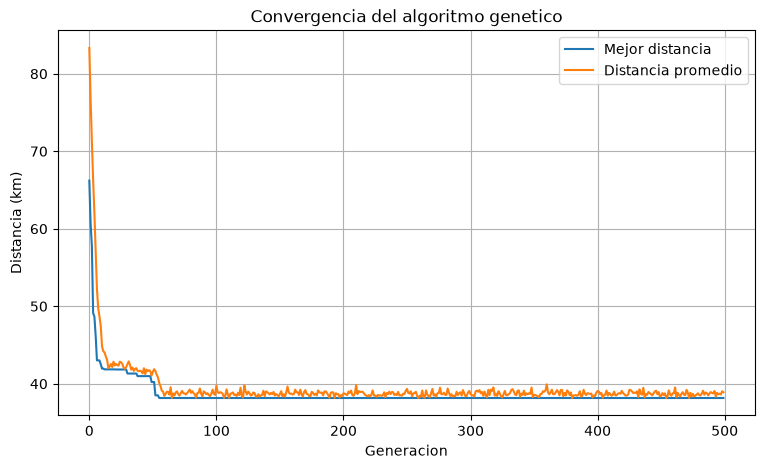

In [34]:
plt.figure(figsize=(9,5))
plt.plot(historial_mejor, label="Mejor distancia")
plt.plot(historial_promedio, label="Distancia promedio")
plt.xlabel("Generacion")
plt.ylabel("Distancia (km)")
plt.title("Convergencia del algoritmo genetico")
plt.legend()
plt.grid(True)
plt.savefig("convergencia.png", dpi=150)
plt.show()

### 10.2 Ruta inicial vs. ruta final

In [35]:
def dibujar_ruta(ruta, titulo, archivo):
    lons = [puntos[i]["longitud"] for i in [0] + ruta + [0]]
    lats = [puntos[i]["latitud"] for i in [0] + ruta + [0]]
    plt.figure(figsize=(8, 8))
    plt.plot(lons, lats, "-o")
    plt.plot(lons[0], lats[0], "r*", markersize=18)

    for i in range(n):
        plt.text(puntos[i]["longitud"], puntos[i]["latitud"], str(i))

    plt.title(titulo)
    plt.xlabel("Longitud")
    plt.ylabel("Latitud")
    plt.grid(True)
    plt.savefig(archivo, dpi=150)
    plt.show()

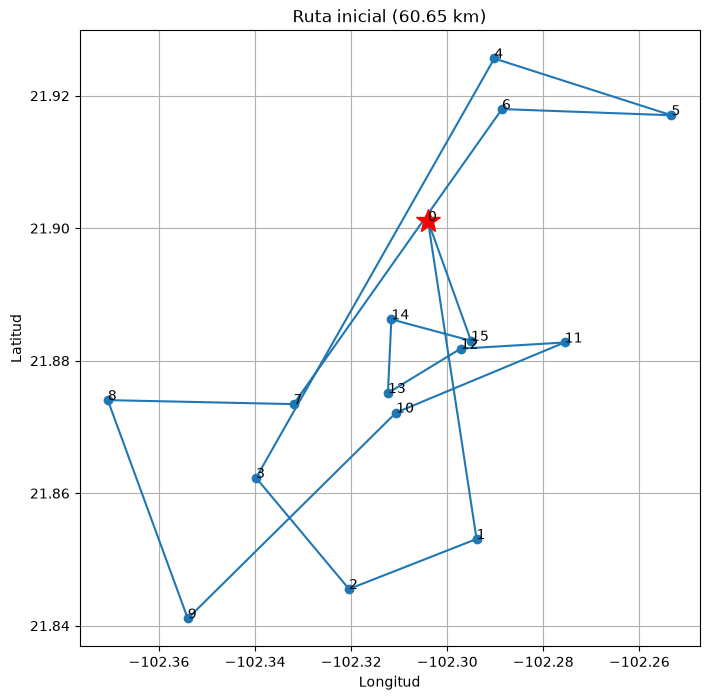

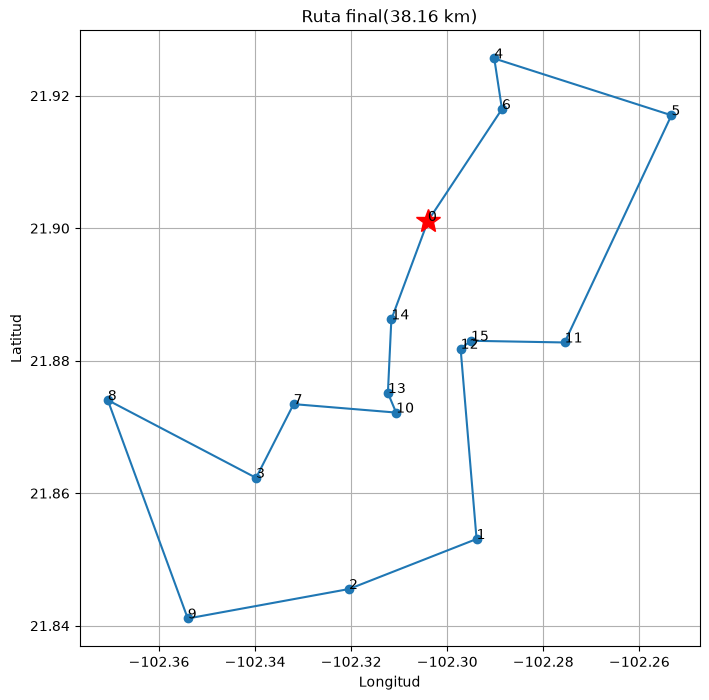

In [36]:
dibujar_ruta(ruta_inicial, f"Ruta inicial ({d_inicial:.2f} km)", "ruta_inicial.png")
dibujar_ruta(mejor_ruta, f"Ruta final({d_final:.2f} km)", "ruta_final.png")

## 11. Experimentacion
Cada configuracion se corre con 10 semillas (1 a 10) y se reporta el promedio, la mejor y la peor distancia.

In [37]:
def correr_ga(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    
    pob = crear_poblacion(TAMANO_POBLACION)
    historial_mejor = []
    
    for gen in range(GENERACIONES):
        dist = [distancia_total(r) for r in pob]
        historial_mejor.append(min(dist))
        pob = nueva_generacion(pob, dist)
    
    dist_final = [distancia_total(r) for r in pob]
    return min(dist_final), historial_mejor, pob[dist_final.index(min(dist_final))]

In [38]:
d, hist, ruta  = correr_ga(42)
print(d, len(hist))

40.126932922515934 500


### 11.1 Tasa de mutacion

In [39]:
semillas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for tasa in [0.01, 0.05, 0.15, 0.30]:
    TASA_MUTACION = tasa
    resultados = [correr_ga(s)[0] for s in semillas]
    print(tasa, sum(resultados) / len(resultados), min(resultados), max(resultados))

TASA_MUTACION = 0.05

0.01 39.497420794363684 38.162686284362124 41.707146543075886
0.05 41.091701997815335 38.162686284362124 43.794154769787156
0.15 40.40022321531459 38.162686284362124 44.15024006887146
0.3 40.72973863801567 38.16268628436214 44.21243038137153


### 11.2 Tamaño del torneo

In [40]:
semillas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for t in [2, 3, 5, 10]:
    TAM_TORNEO = t
    resultados = [correr_ga(s)[0] for s in semillas]
    print(t, sum(resultados) / len(resultados), min(resultados), max(resultados))

TAM_TORNEO = 5

2 40.08758364031807 38.162686284362124 44.43952972038003
3 39.66507784315868 38.162686284362124 44.43909789792249
5 41.091701997815335 38.162686284362124 43.794154769787156
10 40.433366122174725 38.5078430230753 44.13877654816142


### 11.3 Tamaño de poblacion

In [41]:
semillas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for p in [50, 100, 200, 400]:
    TAMANO_POBLACION = p
    resultados = [correr_ga(s)[0] for s in semillas]
    print(p, sum(resultados) / len(resultados), min(resultados), max(resultados))

TAMANO_POBLACION = 100

50 41.66993744571114 38.162686284362124 45.84489180105929
100 41.091701997815335 38.162686284362124 43.794154769787156
200 39.37441869859435 38.162686284362124 42.50600155739181
400 38.86319135791671 38.16268628436214 39.43393128044248


### 11.4 Configuracion combinada

In [42]:
semillas = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
TAMANO_POBLACION = 400
TASA_MUTACION = 0.01
TAM_TORNEO = 3

resultados = [correr_ga(s)[0] for s in semillas]
print(sum(resultados) / len(resultados), min(resultados), max(resultados))

38.62448524749977 38.162686284362124 39.20047409320178


## 12. Resultado Final (población 400, mutación 0.01, torneo 3, semilla 17)

In [43]:
d_opt, hist_opt, ruta_opt = correr_ga(SEMILLA)
print(d_opt)
print(" -> ".join([puntos[i]["nombre"] for i in [0] + ruta_opt + [0]]))
print((d_inicial - d_opt) / d_inicial * 100)

38.162686284362124
Abedul (Punto partida) -> Costco Wholesale -> Centro Comercial Altaria -> Refaccionaria Autozone -> Estadio Victoria -> El Parian -> Catedral de Aguascalientes -> The Home Depot -> H-E-B Santa Monica -> UTA -> Abramex -> Walmart Express -> Cantia -> Iron Black -> El carnes -> Bodega Aurrera -> Abedul (Punto partida)
37.0749473338831


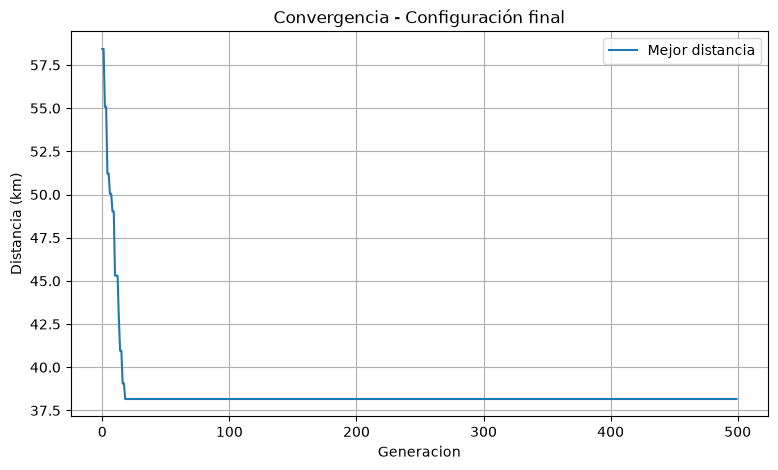

In [44]:
plt.figure(figsize=(9,5))
plt.plot(hist_opt, label="Mejor distancia")
plt.xlabel("Generacion")
plt.ylabel("Distancia (km)")
plt.title("Convergencia - Configuración final")
plt.legend()
plt.grid(True)
plt.savefig("convergencia_final.png", dpi=150)
plt.show()

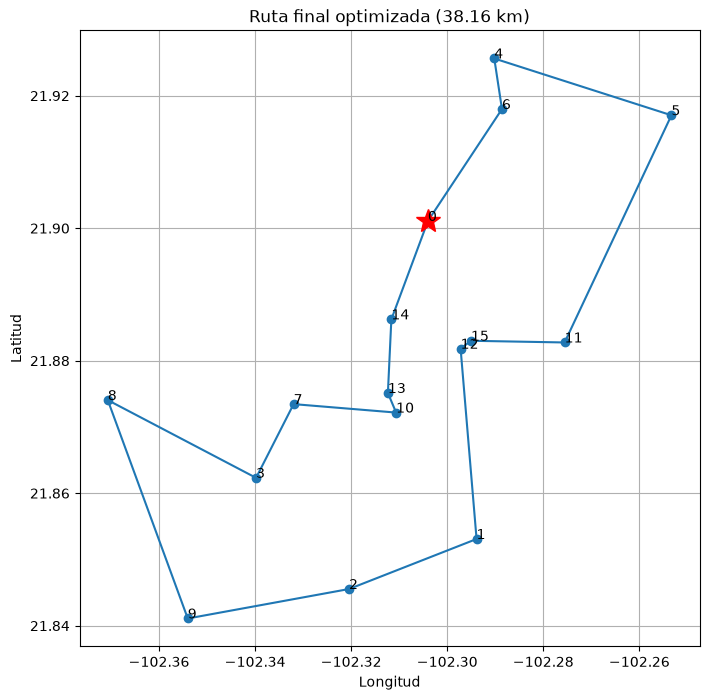

In [45]:
dibujar_ruta(ruta_opt, f"Ruta final optimizada ({d_opt:.2f} km)", "ruta_optima.png")